# 05 — LightGBM seleccionado: adopción, calibración y decisiones por costos

El notebook 04 seleccionó `lightgbm_referencia` por AP media interna. Esa configuración ya se entrenó con todo train en el 03 y tiene su propio Platt, aprendido en validación temprana. En esta etapa verificamos y adoptamos ese ajuste: no repetimos entrenamientos idénticos ni transferimos el calibrador de XGBoost.

Recuperamos sus probabilidades sobre las 42.047 operaciones posteriores y comparamos regla fija, BMR y árbol ponderado. Usamos la misma matriz, los mismos montos originales y los seis Ca hipotéticos del 03. La selección de costos finales sigue pendiente.

Estas operaciones ya se consultaron durante el desarrollo: reproducir sus métricas no es una confirmación independiente. El test permanece sin puntuar. Conservamos las 432 entradas ordinales, las doce discrepancias de tipos y las limitaciones documentadas.

## 1. Qué reutilizamos y por qué

La verificación admite artefactos originales o una reconstrucción con recibo y evidencia completos. Comprobamos la cadena 03→04 antes de deserializar nuestros modelos. Si los parámetros seleccionados no coinciden con el ajuste disponible, nos detenemos: este notebook no cambia el protocolo para entrenar otra configuración automáticamente.

El preprocesador se aprendió con train. Platt pertenece a LightGBM y recibe el logit recortado de sus probabilidades. Los árboles ponderados también se aprendieron solo con train; dependen de Ca y de los atributos, no del predictor probabilístico. Como reutilizamos la misma representación, podemos comprobarlos y reutilizarlos sin volver a ajustarlos.

In [1]:
from pathlib import Path
import gc
import json
import platform
import subprocess
import sys
from datetime import datetime, timezone
from importlib.metadata import version

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src").is_dir() and (p / "notebooks").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from fraud_cost.reference import read_model_frame
from fraud_cost.artifacts import sha256_file, notebook_code_sha256, verify_hashes, verify_reference_artifacts
from fraud_cost.adoption import (
    load_selected_reference, validation_policy, selected_scores, probability_metrics,
    calibration_groups, amount_diagnostics, economic_validation, ATOL, RTOL,
)

TABLES, FIGURES = ROOT / "results/tables", ROOT / "results/figures"
predictor, trees, evidence, reference = load_selected_reference(ROOT)
CA_GRID = (1, 5, 10, 20, 50, 100)
AMOUNT_EDGES = (0, 50, 100, 250, 500, 1000, np.inf)
assert set(CA_GRID) == set(reference["ca_grid"])
input_hashes = {**reference["input_sha256"], **evidence["artifact_sha256"]}
source_paths = ["src/fraud_cost/adoption.py", "src/fraud_cost/artifacts.py", "src/fraud_cost/reference.py", "src/fraud_cost/costs.py"]
source_hashes = {p: sha256_file(ROOT / p) for p in source_paths}
notebook_path = ROOT / "notebooks/05_lightgbm_calibracion_y_costos.ipynb"
code_hash = notebook_code_sha256(notebook_path)
print("Procedencia:", evidence["status"])
print("Adopción:", predictor["adoption_method"])
print("Seleccionado:", predictor["selected_candidate"]["candidate"])
print("Escenarios hipotéticos:", CA_GRID)

Procedencia: verified_reconstruction
Adopción: verified_reuse_stage03_no_refit
Seleccionado: lightgbm_referencia
Escenarios hipotéticos: (1, 5, 10, 20, 50, 100)


## 2. La misma población, sin volver a ajustar

Retenemos únicamente validación y recuperamos la separación temprana/posterior del 03, manteniendo instantes simultáneos juntos. La mitad temprana identifica el origen del calibrador; aquí no la usamos para aprender nada nuevo. El lector recorre los CSV, pero no resumimos etiquetas ni transformamos atributos de test.

Contrastamos IDs, tiempo, monto y etiqueta con los scores XGBoost verificados. Esto comprueba que la comparación usa exactamente las mismas operaciones. El monto económico se conserva en su precisión original, separado de la matriz float32 del predictor.

El dataframe policy conserva ID, tiempo, monto, etiqueta y atributos, pero el predictor solo recibe 432 columnas preparadas. selected_scores devuelve un dataframe de 42.047 filas y siete columnas de control/salida, más una matriz numérica (42.047, 432). El Platt recibe una sola columna de logits. Aquí LightGBM no utiliza el escalador de logística.

In [2]:
manifest = pd.read_parquet(ROOT / "data/interim/split_manifest.parquet", columns=["TransactionID", "split"])
frame = read_model_frame(ROOT / "data/raw", manifest)
policy, windows = validation_policy(frame, reference["validation_calibration_fraction"] if "validation_calibration_fraction" in reference else 0.50)
del frame, manifest
gc.collect()
assert windows["calibration_rows"] == reference["rows"]["calibration"] == 42046
assert windows["policy_rows"] == reference["rows"]["policy"] == 42047
xgb_scores = pd.read_parquet(ROOT / "data/interim/validation_scores.parquet")
identity_columns = ["TransactionID", "TransactionDT", "TransactionAmt", "isFraud"]
pd.testing.assert_frame_equal(policy[identity_columns], xgb_scores[identity_columns], check_exact=True)
scores, matrix = selected_scores(predictor, policy)
assert matrix.shape == (42047, 432)
print(windows)
print("Matriz LightGBM:", matrix.shape, "dtype:", matrix.dtype, "; fraude observado:", f"{scores.isFraud.mean():.2%}")
print("Dataframe de scores:", scores.shape, "; columnas:", scores.columns.tolist())
del xgb_scores, policy
gc.collect()

{'calibration_rows': 42046, 'policy_rows': 42047, 'calibration_time_start': 10126067, 'calibration_time_end': 11293017, 'policy_time_start': 11293020, 'policy_time_end': 12666174}
Matriz LightGBM: (42047, 432) dtype: float32 ; fraude observado: 3.61%
Dataframe de scores: (42047, 7) ; columnas: ['TransactionID', 'TransactionDT', 'TransactionAmt', 'isFraud', 'probability_raw', 'probability_calibrated', 'action_fixed_0_5']


64

## 3. Qué entregan las probabilidades

AP resume el orden de riesgo; Brier y log-loss evalúan probabilidades y deben leerse con la prevalencia. Comparamos raw y Platt sobre las mismas filas. Platt puede mejorar probabilidades sin cambiar AP si conserva el orden. Una mejora global no demuestra calibración suficiente para cada monto o región de riesgo.

Estas métricas deben reproducir las del LightGBM del 03 dentro de tolerancias fijadas de antemano. La comprobación permite detectar una asociación incorrecta de modelo, preprocesador o calibrador; no produce evidencia independiente.

Mantenemos las seis métricas del 03: AP, Brier, log-loss, recall, precision y bloqueo de legítimas. Las tres últimas usan el corte fijo 0,5. Las métricas raw del 04 pertenecen a futuros internos distintos y no se restan de estas como si midieran una mejora sobre la misma población. La tabla económica posterior cambia la unidad de comparación a política por Ca.

,model,probability,rows,frauds,fraud_rate,mean_probability,average_precision,brier_score,log_loss,recall_at_0_5,precision_at_0_5,legitimate_block_rate,block_count
0,lightgbm,raw,42047,1517,0.03608,0.02762,0.5044,0.02435,0.09750,0.28741,0.80295,0.00264,543
1,lightgbm,platt,42047,1517,0.03608,0.03029,0.5044,0.02406,0.09645,0.30850,0.78523,0.00316,596


,amount_band,rows,frauds,observed_rate,mean_probability,observed_fraud_amount,expected_fraud_amount_raw,expected_fraud_amount_platt
0,"[0.0, 50.0)",13918,513,0.0369,0.0357,14055.747,12285.3514,13297.9862
1,"[50.0, 100.0)",11495,355,0.0309,0.0233,24520.048,16749.5696,18403.5498
2,"[100.0, 250.0)",12075,395,0.0327,0.0264,61271.060,43103.4707,47750.1470
3,"[250.0, 500.0)",2742,125,0.0456,0.0369,43417.257,32034.1479,35897.6558
4,"[500.0, 1000.0)",1209,116,0.0959,0.0610,88800.310,48245.7075,54610.9860
5,"[1000.0, inf)",608,13,0.0214,0.0270,22472.390,23085.2230,25765.2582


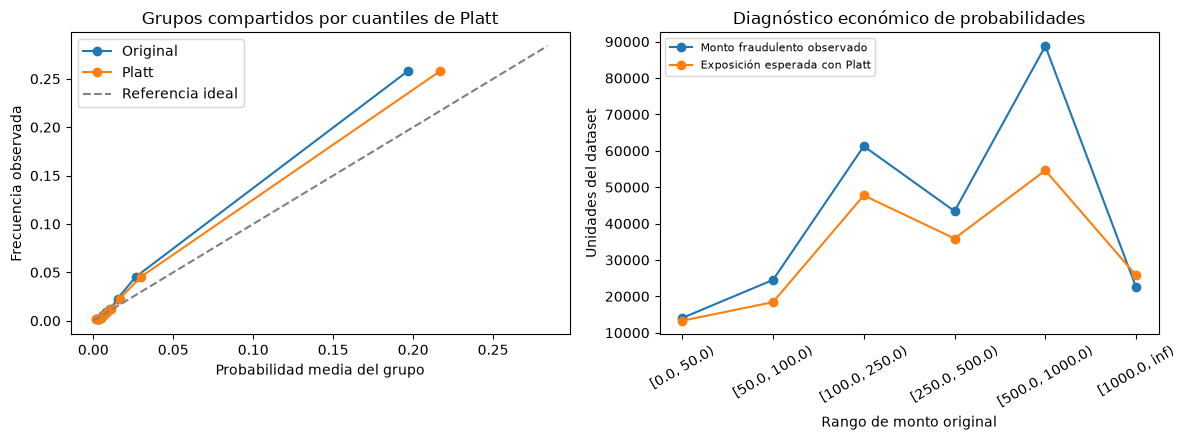

In [3]:
metrics = probability_metrics(scores)
required_metrics = {"average_precision", "brier_score", "log_loss", "recall_at_0_5", "precision_at_0_5", "legitimate_block_rate"}
assert required_metrics.issubset(metrics.columns)
assert set(metrics.probability) == {"raw", "platt"}
historical = pd.read_csv(TABLES / "modelos_calibracion_validation.csv")
for row in metrics.itertuples():
    expected = historical.loc[historical.modelo.eq("lightgbm") & historical.probabilidad.eq(row.probability)].iloc[0]
    np.testing.assert_allclose([row.average_precision, row.brier_score, row.log_loss, row.mean_probability],
        expected[["average_precision", "brier_score", "log_loss", "probabilidad_media"]].to_numpy(dtype=float), atol=ATOL, rtol=RTOL)
metrics.to_csv(TABLES / "lightgbm_metricas_validation.csv", index=False)
groups = calibration_groups(scores, bins=10)
groups.to_csv(TABLES / "lightgbm_calibracion_grupos.csv", index=False)
amounts = amount_diagnostics(scores, AMOUNT_EDGES)
amounts.to_csv(TABLES / "lightgbm_calibracion_montos.csv", index=False)
display(metrics.round(5))
display(amounts.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for column, label in [("mean_raw", "Original"), ("mean_platt", "Platt")]:
    axes[0].plot(groups[column], groups.observed_rate, marker="o", label=label)
limit = min(1, 1.1 * max(groups.observed_rate.max(), groups.mean_raw.max(), groups.mean_platt.max()))
axes[0].plot([0, limit], [0, limit], "--", color="gray", label="Referencia ideal")
axes[0].set(xlabel="Probabilidad media del grupo", ylabel="Frecuencia observada", title="Grupos compartidos por cuantiles de Platt")
axes[0].legend()
axes[1].plot(amounts.amount_band, amounts.observed_fraud_amount, marker="o", label="Monto fraudulento observado")
axes[1].plot(amounts.amount_band, amounts.expected_fraud_amount_platt, marker="o", label="Exposición esperada con Platt")
axes[1].tick_params(axis="x", rotation=30)
axes[1].set(xlabel="Rango de monto original", ylabel="Unidades del dataset", title="Diagnóstico económico de probabilidades")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "lightgbm_calibracion_validation.png", dpi=160, bbox_inches="tight")
plt.show()

## 4. De la probabilidad a la acción

La etiqueta convencional conserva el corte 0,5. BMR compara el riesgo esperado de aprobar, p×A, con Ca: interviene solo si p×A>Ca y aprueba en empate. Intervenir cuesta Ca en ambas clases; aprobar fraude cuesta A y aprobar una legítima, cero. Con A≤Ca no resulta estrictamente beneficioso intervenir bajo esta matriz.

Reutilizamos un árbol por Ca; sus salidas son acciones y no probabilidades calibradas de fraude. La función económica compartida calcula costo administrativo más monto fraudulento aprobado. Diferenciamos ahorro frente a la mejor referencia trivial y mejora frente a la regla fija del propio LightGBM.

Añadimos la diferencia respecto al costo XGBoost del 03 para contextualizar el cambio de predictor. Una diferencia negativa favorece a LightGBM. Los árboles deben conservar su costo porque no cambiaron su ajuste, su matriz ni sus operaciones.

,administrative_cost_ca,strategy,cost_total_proxy,administrative_cost_total,missed_fraud_amount,fraud_recall,legitimate_block_rate,savings_fraction_vs_fixed_proxy,cost_difference_vs_xgboost
0,1.0,fixed_0_5,192740.916,596.0,192144.916,0.3085,0.0032,0.0000,-7023.299
1,1.0,bmr,22990.589,14984.0,8006.589,0.8728,0.3370,0.8807,-2596.903
2,1.0,cost_sensitive_tree,41177.404,15801.0,25376.404,0.7713,0.3610,0.7864,0.000
3,5.0,fixed_0_5,195124.916,2980.0,192144.916,0.3085,0.0032,0.0000,-6871.299
4,5.0,bmr,61579.254,26990.0,34589.254,0.6691,0.1081,0.6844,-4742.958
5,5.0,cost_sensitive_tree,90918.330,30685.0,60233.330,0.5517,0.1308,0.5341,0.000
6,10.0,fixed_0_5,198104.916,5960.0,192144.916,0.3085,0.0032,0.0000,-6681.299
7,10.0,bmr,84169.725,31860.0,52309.725,0.5557,0.0578,0.5751,-4013.013
8,10.0,cost_sensitive_tree,125992.237,32900.0,93092.237,0.4054,0.0660,0.3640,0.000
9,20.0,fixed_0_5,204064.916,11920.0,192144.916,0.3085,0.0032,0.0000,-6301.299


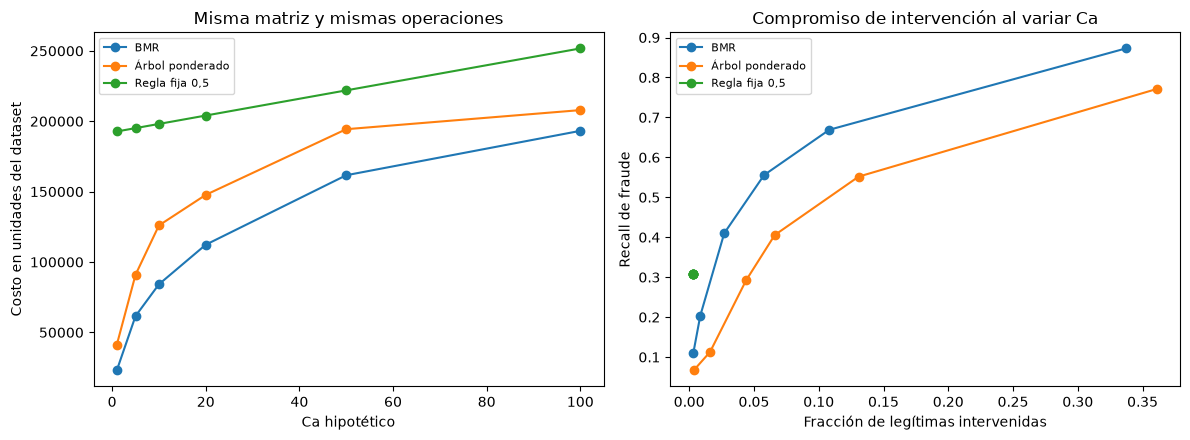

In [4]:
costs, actions, sensitivity = economic_validation(scores, matrix, trees, CA_GRID)
historical_costs = pd.read_csv(TABLES / "costos_validation_sensibilidad.csv")
xgb_reference = historical_costs[["administrative_cost_ca", "strategy", "cost_total_proxy"]].rename(columns={"cost_total_proxy":"xgboost_reference_cost"})
costs = costs.merge(xgb_reference, on=["administrative_cost_ca", "strategy"], validate="one_to_one")
costs["cost_difference_vs_xgboost"] = costs.cost_total_proxy - costs.xgboost_reference_cost
tree_rows = costs.loc[costs.strategy.eq("cost_sensitive_tree")]
np.testing.assert_allclose(tree_rows.cost_total_proxy, tree_rows.xgboost_reference_cost, atol=ATOL, rtol=RTOL)
costs.to_csv(TABLES / "lightgbm_costos_validation.csv", index=False)
sensitivity.to_csv(TABLES / "lightgbm_bmr_raw_platt.csv", index=False)
display(costs[["administrative_cost_ca", "strategy", "cost_total_proxy", "administrative_cost_total",
               "missed_fraud_amount", "fraud_recall", "legitimate_block_rate",
               "savings_fraction_vs_fixed_proxy", "cost_difference_vs_xgboost"]].round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
labels = {"fixed_0_5":"Regla fija 0,5", "bmr":"BMR", "cost_sensitive_tree":"Árbol ponderado"}
for strategy, group in costs.groupby("strategy"):
    axes[0].plot(group.administrative_cost_ca, group.cost_total_proxy, marker="o", label=labels[strategy])
    axes[1].plot(group.legitimate_block_rate, group.fraud_recall, marker="o", label=labels[strategy])
axes[0].set(xlabel="Ca hipotético", ylabel="Costo en unidades del dataset", title="Misma matriz y mismas operaciones")
axes[1].set(xlabel="Fracción de legítimas intervenidas", ylabel="Recall de fraude", title="Compromiso de intervención al variar Ca")
for ax in axes: ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "lightgbm_costos_validation.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. Calibración y costo no son la misma medición

La tabla raw/Platt aplica BMR con cada probabilidad y mantiene la regla fija calibrada como referencia común del diagnóstico. No incorpora una cuarta política principal ni selecciona otro calibrador por el ahorro observado. Que Brier mejore no garantiza que el costo realizado mejore en cada Ca: pequeñas diferencias cerca de la frontera pA=Ca pueden cambiar acciones sobre montos distintos.

No usamos el costo mínimo de esta tabla para elegir Ca. Los valores son escenarios hipotéticos en unidades del dataset y no estimaciones de gastos operativos reales.

In [5]:
comparison = sensitivity.pivot(index="administrative_cost_ca", columns="probability", values="cost_total_proxy")
comparison["platt_minus_raw"] = comparison.platt - comparison.raw
display(comparison.round(4))
example = costs.loc[costs.administrative_cost_ca.eq(10)]
display(example[["strategy", "policy_block_count", "frauds_blocked", "legitimate_block_count",
                 "cost_total_proxy", "savings_fraction_vs_reference", "savings_fraction_vs_fixed_proxy"]].round(4))
print("Probabilidades y acciones ya fueron consultadas como desarrollo; no son una prueba independiente.")
print("Test sin puntuar. Escenarios de Ca y protocolo final todavía pendientes.")

probability,platt,raw,platt_minus_raw
administrative_cost_ca,,,
1.0,22990.589,22793.767,196.822
5.0,61579.254,63499.839,-1920.585
10.0,84169.725,86759.498,-2589.773
20.0,112284.115,114689.943,-2405.828
50.0,161647.515,166296.732,-4649.217
100.0,193192.685,192708.944,483.741


,strategy,policy_block_count,frauds_blocked,legitimate_block_count,cost_total_proxy,savings_fraction_vs_reference,savings_fraction_vs_fixed_proxy
6,fixed_0_5,596,468,128,198104.916,0.2217,0.0000
7,bmr,3186,843,2343,84169.725,0.6693,0.5751
8,cost_sensitive_tree,3290,615,2675,125992.237,0.5050,0.3640


Probabilidades y acciones ya fueron consultadas como desarrollo; no son una prueba independiente.
Test sin puntuar. Escenarios de Ca y protocolo final todavía pendientes.


## 6. Artefactos propios de LightGBM y procedencia

Guardamos un paquete mínimo con el modelo, el preprocesador y su Platt; los árboles verificados siguen en su archivo de origen. Probabilidades y acciones por operación quedan locales e ignoradas por Git. Las tablas, figuras y registro de esta etapa identifican LightGBM expresamente y no sustituyen los scores XGBoost del 03.

El registro señala reutilización, no un nuevo ajuste. Conserva los hashes efectivos de los artefactos originales o reconstruidos, las ventanas de validación, los escenarios y la referencia a la selección del 04. Antes de evaluar test será necesario congelar el protocolo y documentar la justificación de costos y las limitaciones.

In [6]:
model_path = ROOT / "results/models/lightgbm_seleccionado_platt.joblib"
scores_path = ROOT / "data/interim/lightgbm_validation_scores.parquet"
actions_path = ROOT / "data/interim/lightgbm_validation_actions.parquet"
joblib.dump(predictor, model_path)
scores.to_parquet(scores_path, index=False)
actions.to_parquet(actions_path, index=False)
verify_hashes(ROOT, {**input_hashes, **source_hashes})
if notebook_code_sha256(notebook_path) != code_hash:
    raise RuntimeError("Cambió el código de esta etapa durante la ejecución")
verify_reference_artifacts(ROOT)
output_paths = ["results/models/lightgbm_seleccionado_platt.joblib", "data/interim/lightgbm_validation_scores.parquet",
    "data/interim/lightgbm_validation_actions.parquet", "results/tables/lightgbm_metricas_validation.csv",
    "results/tables/lightgbm_calibracion_grupos.csv", "results/tables/lightgbm_calibracion_montos.csv",
    "results/tables/lightgbm_costos_validation.csv", "results/tables/lightgbm_bmr_raw_platt.csv",
    "results/figures/lightgbm_calibracion_validation.png", "results/figures/lightgbm_costos_validation.png"]
record_paths = ["results/tables/comparacion_modelos_config.json", "results/tables/seleccion_ordinal_config.json"]
if evidence["status"] == "verified_reconstruction":
    record_paths.append("results/tables/recuperacion_03_config.json")
record = {
    "status":"complete", "created_utc":datetime.now(timezone.utc).isoformat(),
    "model":"lightgbm", "selected_candidate":predictor["selected_candidate"],
    "adoption_method":predictor["adoption_method"], "source_artifact_status":evidence["status"],
    "new_model_fitted":False, "new_calibrator_fitted":False, "cost_trees_refitted":False,
    "model_fit_origin":"stage03_train", "calibrator_fit_origin":"stage03_validation_early",
    "reference_metrics_verified":True, "cost_tree_reference_verified":True,
    "comparison_atol":ATOL, "comparison_rtol":RTOL, "validation_windows":windows,
    "test_evaluated":False, "costs_hypothetical":True, "final_protocol_frozen":False,
    "validation_policy_previously_consulted":True, "ca_grid":list(CA_GRID),
    "amount_edges":["0","50","100","250","500","1000","inf"],
    "input_sha256":input_hashes, "source_sha256":source_hashes,
    "historical_record_sha256":{p:sha256_file(ROOT / p) for p in record_paths},
    "notebook_code_sha256":code_hash, "output_sha256":{p:sha256_file(ROOT / p) for p in output_paths},
    "python":platform.python_version(), "versions":{p:version(p) for p in ["numpy","pandas","scikit-learn","lightgbm","joblib"]},
    "git_base_commit":subprocess.check_output(["git","rev-parse","HEAD"],cwd=ROOT,text=True).strip(),
    "working_tree_dirty":bool(subprocess.check_output(["git","status","--porcelain"],cwd=ROOT,text=True).strip()),
}
(TABLES / "lightgbm_adopcion_config.json").write_text(json.dumps(record, ensure_ascii=False, indent=2), encoding="utf-8")
print("LightGBM adoptado y registrado. No se entrenó de nuevo ni se puntuó test.")

LightGBM adoptado y registrado. No se entrenó de nuevo ni se puntuó test.


## 7. Qué encontramos y qué sigue

El modelo adoptado conserva AP **0.50440**. Platt mejora Brier y log-loss, pero la media calibrada **3.03%** queda por debajo del **3.61%** observado. La subestimación de exposición es especialmente visible en la banda [500,1000); no se presenta igual en todas las bandas.

Con Ca=10, BMR cuesta **84,169.73** unidades y mejora **57.51%** frente al corte fijo del propio LightGBM. Interviene 3,186 operaciones, con recall **55.57%** y bloqueo de legítimas **5.78%**. Leemos el ahorro junto con este incremento de intervenciones.

BMR con LightGBM obtiene menor costo que BMR con XGBoost en 6 de los seis escenarios de este bloque. Sin embargo, Platt mejora el costo BMR frente a raw solo en 4 de seis. La calidad probabilística global y el costo realizado no son intercambiables.

La adopción quedó verificada, sin nuevos ajustes y sin puntuar test. El próximo paso es estudiar estabilidad por subperiodos y errores de mayor monto. Ca continúa siendo hipotético y no elegimos un valor por el ahorro de estas tablas. El informe 05 conserva los resultados completos y su alcance.
